Outlier Analysis

age,trestbps,chol,oldpeak,thalch

In [1]:
import sys
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.append(project_root)

from src.data.data_loader import load_data

df = load_data('D:\\Heart-Disease-Prediction\\data\\processed\\cleaned_heart.csv')

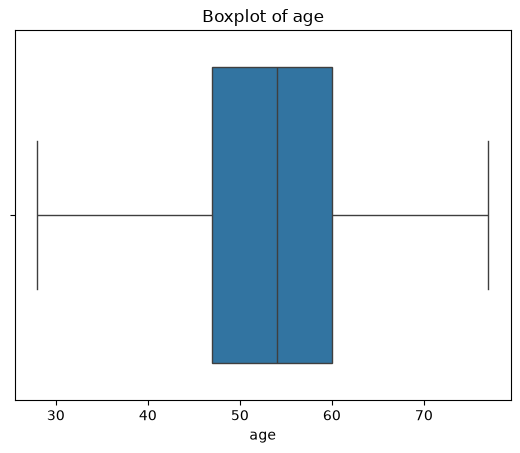

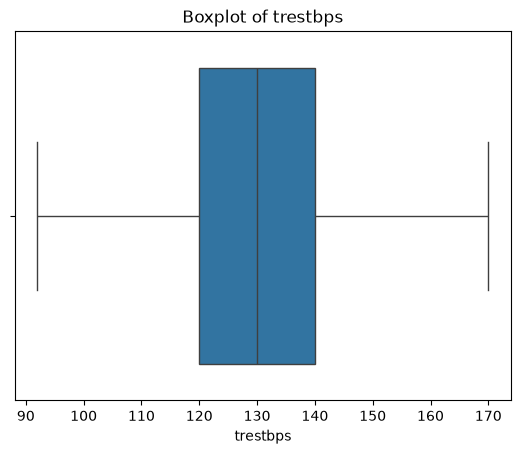

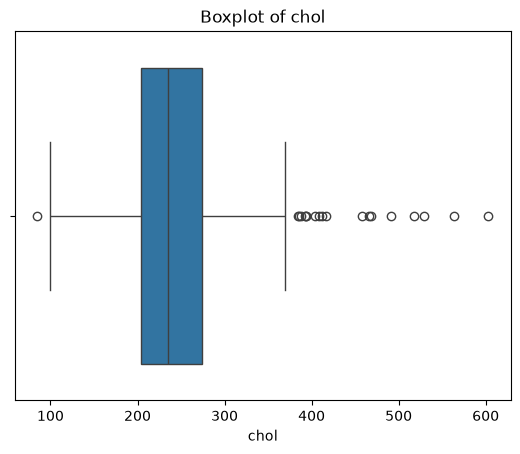

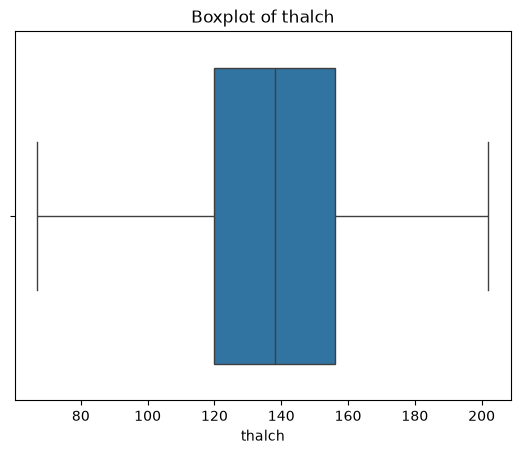

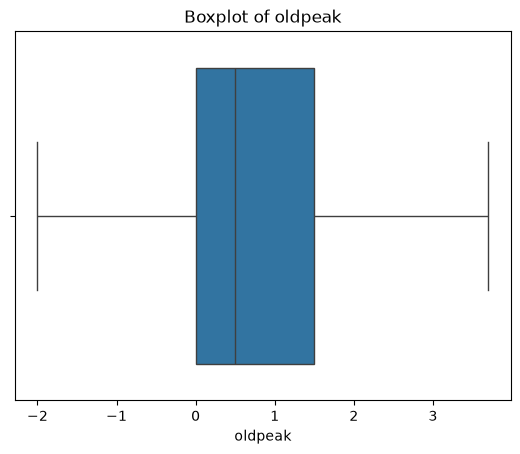

In [2]:
numerical_columns = [
    'age',
    'trestbps',
    'chol',
    'thalch',
    'oldpeak'
]
for col in numerical_columns:
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [3]:
for col in numerical_columns:
    print(f"\n\nDescribe {col}:\n")
    print(df[col].describe())



Describe age:

count    876.000000
mean      53.345890
std        9.495635
min       28.000000
25%       47.000000
50%       54.000000
75%       60.000000
max       77.000000
Name: age, dtype: float64


Describe trestbps:

count    876.000000
mean     130.602740
std       15.720478
min       92.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      170.000000
Name: trestbps, dtype: float64


Describe chol:

count    715.000000
mean     243.923077
std       58.084271
min       85.000000
25%      204.000000
50%      235.000000
75%      274.000000
max      603.000000
Name: chol, dtype: float64


Describe thalch:

count    876.00000
mean     137.90411
std       24.80691
min       67.00000
25%      120.00000
50%      138.00000
75%      156.00000
max      202.00000
Name: thalch, dtype: float64


Describe oldpeak:

count    876.000000
mean       0.796347
std        0.956499
min       -2.000000
25%        0.000000
50%        0.500000
75%        1.500000
max        3.7000

In [4]:
def outlier_analysis(df, numerical_columns):
    for col in numerical_columns:
            print(f'\n\nColumns: {col}')
            minimum,Q1,median,Q3,maximum=np.quantile(df[col],[0,0.25,0.50,0.75,1.0])
            print(f'\n"minimum:"{minimum}  "Quartile_1: "{Q1} "Median: "{median} "Quartile_3: "{Q3} "Maximum: "{maximum}')
            IQR=Q3-Q1
            print("Interquartile Range: ",IQR)
            lower_fence=Q1-1.5*(IQR)
            higher_fence=Q3+1.5*(IQR)
            outliers = df[(df[col] < lower_fence) | (df[col] > higher_fence)]
            print('lower_bound :', lower_fence)
            print('upper_bound :', higher_fence)
            print('num_outliers :', len(outliers))


outlier_analysis(df,numerical_columns=numerical_columns)



Columns: age

"minimum:"28.0  "Quartile_1: "47.0 "Median: "54.0 "Quartile_3: "60.0 "Maximum: "77.0
Interquartile Range:  13.0
lower_bound : 27.5
upper_bound : 79.5
num_outliers : 0


Columns: trestbps

"minimum:"92.0  "Quartile_1: "120.0 "Median: "130.0 "Quartile_3: "140.0 "Maximum: "170.0
Interquartile Range:  20.0
lower_bound : 90.0
upper_bound : 170.0
num_outliers : 0


Columns: chol

"minimum:"nan  "Quartile_1: "nan "Median: "nan "Quartile_3: "nan "Maximum: "nan
Interquartile Range:  nan
lower_bound : nan
upper_bound : nan
num_outliers : 0


Columns: thalch

"minimum:"67.0  "Quartile_1: "120.0 "Median: "138.0 "Quartile_3: "156.0 "Maximum: "202.0
Interquartile Range:  36.0
lower_bound : 66.0
upper_bound : 210.0
num_outliers : 0


Columns: oldpeak

"minimum:"-2.0  "Quartile_1: "0.0 "Median: "0.5 "Quartile_3: "1.5 "Maximum: "3.7
Interquartile Range:  1.5
lower_bound : -2.25
upper_bound : 3.75
num_outliers : 0


cholesterol values chol:

In [5]:
# Check zero cholesterol values
print("Zero cholesterol count:", (df['chol'] == 0).sum())

# Display records with zero cholesterol
df.loc[df['chol'] == 0, ['chol', 'num']]

Zero cholesterol count: 0


,chol,num


In [6]:
# Find values above the IQR upper bound
chol_high_outliers = df[df['chol'] > 400.875]

print("High cholesterol outliers:",
      len(chol_high_outliers))

display(chol_high_outliers[['chol', 'num']].sort_values(
    by='chol',
    ascending=False
))

High cholesterol outliers: 12


,chol,num
525,603.0,1
146,564.0,0
507,529.0,1
545,518.0,1
560,491.0,1
415,468.0,0
479,466.0,1
763,458.0,0
47,417.0,0
356,412.0,0


In [7]:
Q1 = df['chol'].quantile(0.25)
Q3 = df['chol'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

low_outliers = df[df['chol'] < lower_bound]
high_outliers = df[df['chol'] > upper_bound]

print("Lower outliers:", len(low_outliers))
print("Upper outliers:", len(high_outliers))
print("Total outliers:", len(low_outliers) + len(high_outliers))

Lower outliers: 1
Upper outliers: 18
Total outliers: 19


In [8]:
df['chol'] = df['chol'].replace(0, np.nan)

print("Missing cholesterol values:", df['chol'].isnull().sum())

Missing cholesterol values: 161


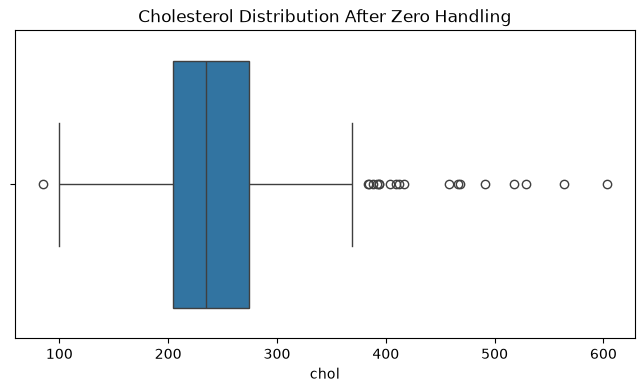

In [9]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['chol'])

plt.title('Cholesterol Distribution After Zero Handling')
plt.show()

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 876 entries, 0 to 875
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        876 non-null    int64  
 1   age       876 non-null    int64  
 2   sex       876 non-null    str    
 3   dataset   876 non-null    str    
 4   cp        876 non-null    str    
 5   trestbps  876 non-null    int64  
 6   chol      715 non-null    float64
 7   fbs       876 non-null    bool   
 8   restecg   876 non-null    str    
 9   thalch    876 non-null    int64  
 10  exang     876 non-null    bool   
 11  oldpeak   876 non-null    float64
 12  slope     876 non-null    str    
 13  num       876 non-null    int64  
dtypes: bool(2), float64(2), int64(5), str(5)
memory usage: 84.0 KB


### Cholesterol (`chol`) Outlier Analysis

The IQR method identified 185 potential outliers in the cholesterol column.

- **172 lower outliers:** All observations had a value of zero. These values were investigated and treated as missing (`NaN`) because zero represents an unavailable cholesterol measurement in the records.
- **13 upper outliers:** These observations had values above the IQR upper boundary of 400.875. They will be retained unless further investigation identifies invalid measurements.

**Decision:** Zero values are converted to missing values. The 13 high cholesterol measurements are retained to avoid losing potentially meaningful medical information. Missing-value imputation will be performed later in the model preprocessing pipeline.

In [11]:
df['chol'] = df['chol'].fillna(round(df['chol'].mean()))

In [12]:
def remove_outliers(df, numerical_columns):
    for col in numerical_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    return df

numerical_columns = [
    'trestbps',
    'thalch',
    'oldpeak'
]

df = remove_outliers(df, numerical_columns)

In [13]:
df.shape

(876, 14)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 876 entries, 0 to 875
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        876 non-null    int64  
 1   age       876 non-null    int64  
 2   sex       876 non-null    str    
 3   dataset   876 non-null    str    
 4   cp        876 non-null    str    
 5   trestbps  876 non-null    int64  
 6   chol      876 non-null    float64
 7   fbs       876 non-null    bool   
 8   restecg   876 non-null    str    
 9   thalch    876 non-null    int64  
 10  exang     876 non-null    bool   
 11  oldpeak   876 non-null    float64
 12  slope     876 non-null    str    
 13  num       876 non-null    int64  
dtypes: bool(2), float64(2), int64(5), str(5)
memory usage: 84.0 KB


In [15]:
from pathlib import Path

project_root = Path.cwd().parent

print(project_root)
print(type(project_root))
processed_dir = project_root /'data'/'processed'

processed_dir.mkdir(
    parents=True,
    exist_ok=True
)

processed_path = processed_dir / 'cleaned_heart.csv'

df.to_csv(
    processed_path,
    index=False
)


if processed_path.exists():
    print("Dataset saved successfully!")
    print("File location:", processed_path.resolve())
    print("File size:", processed_path.stat().st_size, "bytes")
else:
    print("Dataset saving failed!")

d:\Heart-Disease-Prediction
<class 'pathlib.WindowsPath'>
Dataset saved successfully!
File location: D:\Heart-Disease-Prediction\data\processed\cleaned_heart.csv
File size: 75177 bytes


In [16]:
df.head(5)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,num
0,1,63,Male,Cleveland,typical angina,145,233.0,True,lv hypertrophy,150,False,2.3,downsloping,0
1,2,67,Male,Cleveland,asymptomatic,160,286.0,False,lv hypertrophy,108,True,1.5,flat,2
2,3,67,Male,Cleveland,asymptomatic,120,229.0,False,lv hypertrophy,129,True,2.6,flat,1
3,4,37,Male,Cleveland,non-anginal,130,250.0,False,normal,187,False,3.5,downsloping,0
4,5,41,Female,Cleveland,atypical angina,130,204.0,False,lv hypertrophy,172,False,1.4,upsloping,0
